In [51]:
import os, glob, pickle
from pprint import pprint
import numpy as np

# ===== 0. 데이터 경로 설정 =====
data_dir = "tactile_data_new/episode_0002"

print("Data dir:", data_dir)

# ===== 1. 파일 리스트 =====
pkl_files = sorted([
    os.path.join(data_dir, f) 
    for f in os.listdir(data_dir) 
    if f.endswith(".pkl") and f != "metadata.pkl"
])

print("Number of data files:", len(pkl_files))
print("First 5 files:")
for f in pkl_files[:5]:
    print(f)

# ===== 2. metadata 확인 =====
meta_path = os.path.join(data_dir, "metadata.pkl")
if os.path.exists(meta_path):
    with open(meta_path, "rb") as f:
        metadata = pickle.load(f)
    print("\n[Metadata]")
    pprint(metadata)
else:
    print("\n[Metadata] 없음")

# ===== 3. 샘플 하나 열기 =====
sample_path = pkl_files[0]
print("\n[Sample file]:", sample_path)

with open(sample_path, "rb") as f:
    sample = pickle.load(f)

print("Sample type:", type(sample))

# ===== 4. 구조 탐색 =====
def inspect_obj(obj, name="root", depth=0, max_depth=2):
    indent = "  " * depth
    
    if depth > max_depth:
        return
    
    if isinstance(obj, dict):
        print(f"{indent}{name}: dict, keys={list(obj.keys())}")
        for k, v in obj.items():
            inspect_obj(v, f"{name}.{k}", depth+1, max_depth)
    
    elif isinstance(obj, (list, tuple)):
        print(f"{indent}{name}: {type(obj).__name__}, len={len(obj)}")
        if len(obj) > 0:
            inspect_obj(obj[0], f"{name}[0]", depth+1, max_depth)
    
    elif isinstance(obj, np.ndarray):
        print(f"{indent}{name}: ndarray, shape={obj.shape}, dtype={obj.dtype}")
    
    else:
        try:
            import torch
            if isinstance(obj, torch.Tensor):
                print(f"{indent}{name}: torch.Tensor, shape={tuple(obj.shape)}, dtype={obj.dtype}")
                return
        except:
            pass
        
        print(f"{indent}{name}: {type(obj)}")

print("\n[Sample structure]")
inspect_obj(sample, max_depth=3)

# ===== 5. timestamp 분석 =====
timestamps = []
for f in pkl_files:
    ts = os.path.splitext(os.path.basename(f))[0]
    try:
        timestamps.append(float(ts))
    except:
        pass

timestamps = sorted(timestamps)

if len(timestamps) > 1:
    diffs = np.diff(timestamps)
    print("\n[Timing info]")
    print("Mean dt:", diffs.mean())
    print("Approx Hz:", 1.0 / diffs.mean())

Data dir: tactile_data_new/episode_0002
Number of data files: 129
First 5 files:
tactile_data_new/episode_0002/1775781191.657130.pkl
tactile_data_new/episode_0002/1775781191.689400.pkl
tactile_data_new/episode_0002/1775781191.718670.pkl
tactile_data_new/episode_0002/1775781191.754405.pkl
tactile_data_new/episode_0002/1775781191.792828.pkl

[Metadata]
{'left_config': {'data_sampling_rate': 120,
                 'data_shape': (240, 320, 5),
                 'id_0': '2505150094',
                 'id_1': '2505150094',
                 'img_height': 240,
                 'img_width': 320,
                 'sampling_rate': 120,
                 'viz_sampling_rate': 60},
 'left_type': 'daimon',
 'right_config': {'baudrate': 115200,
                  'data_shape': (5, 3),
                  'dtype': 'float32',
                  'num_mags': 5,
                  'port_left': '/dev/eflesh_s1',
                  'port_right': '/dev/eflesh_s1',
                  'sampling_rate': 100,
              

In [52]:
import pickle
import numpy as np
import torch

sample_path = pkl_files[0]

with open(sample_path, "rb") as f:
    sample = pickle.load(f)

print("=== Sample shape summary ===")

for k, v in sample.items():
    if isinstance(v, np.ndarray):
        print(f"{k}: np.ndarray, shape={v.shape}, dtype={v.dtype}")
    
    elif isinstance(v, torch.Tensor):
        print(f"{k}: torch.Tensor, shape={tuple(v.shape)}, dtype={v.dtype}")
    
    else:
        print(f"{k}: {type(v)}")

=== Sample shape summary ===
ts: <class 'float'>
s0: np.ndarray, shape=(240, 320, 5), dtype=float16
s1: np.ndarray, shape=(5, 3), dtype=float16
img0: np.ndarray, shape=(480, 640, 3), dtype=uint8
img1: np.ndarray, shape=(480, 640, 3), dtype=uint8


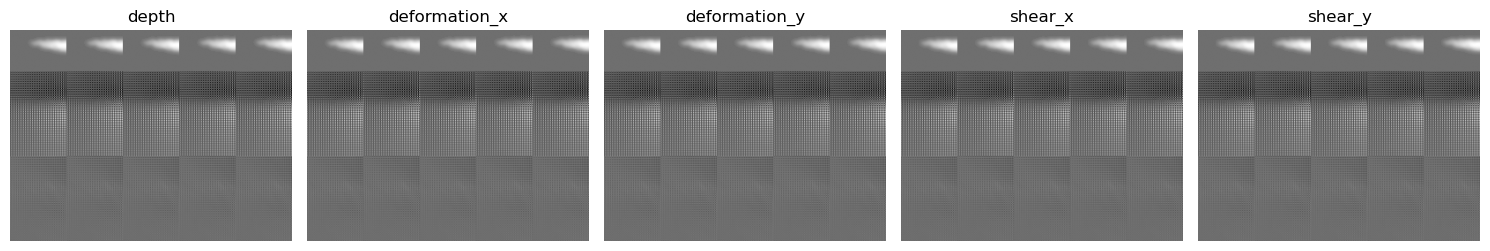

In [55]:
import matplotlib.pyplot as plt
import pickle

# 샘플 로드
with open(pkl_files[80], "rb") as f:
    d = pickle.load(f)

s0 = d["s0"]  # (240, 320, 5)

channel_names = [
    "depth",
    "deformation_x",
    "deformation_y",
    "shear_x",
    "shear_y"
]

plt.figure(figsize=(15, 6))

for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(s0[:, :, i], cmap="gray")
    plt.title(channel_names[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [58]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

# ===== 파일 로드 =====
pkl_path = pkl_files[80]   # 이미 네가 만든 pkl_files 사용

with open(pkl_path, "rb") as f:
    d = pickle.load(f)

s0_wrong = d["s0"]   # shape = (240, 320, 5), but wrongly reshaped before saving

print("loaded s0 shape:", s0_wrong.shape, s0_wrong.dtype)

# ===== 잘못 저장된 s0 -> 원래 flat 복원 =====
flat = s0_wrong.reshape(-1)

H, W = 240, 320
N = H * W

# 원래 저장 순서:
# [depth.flatten(), deformation.flatten(), shear.flatten()]
depth = flat[:N].reshape(H, W)
deformation = flat[N:3*N].reshape(H, W, 2)
shear = flat[3*N:5*N].reshape(H, W, 2)

# 최종 올바른 5채널로 재조립
s0_correct = np.concatenate([
    depth[..., None],
    deformation,
    shear
], axis=-1)

print("reconstructed shape:", s0_correct.shape)

loaded s0 shape: (240, 320, 5) float16
reconstructed shape: (240, 320, 5)


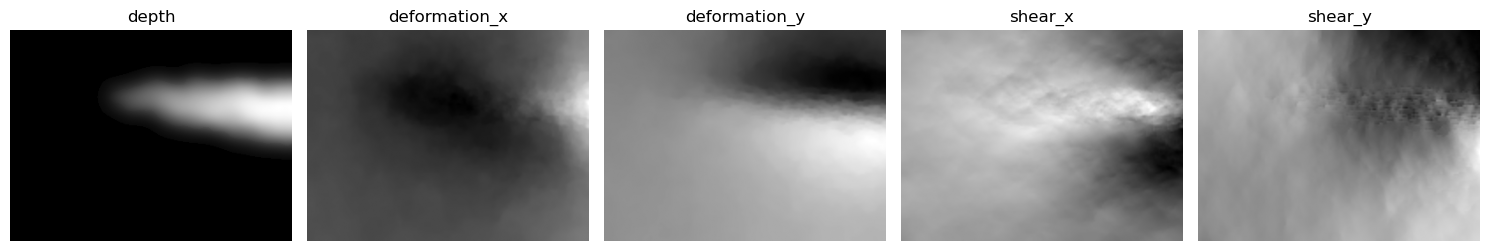

In [59]:
import matplotlib.pyplot as plt

channel_names = [
    "depth",
    "deformation_x",
    "deformation_y",
    "shear_x",
    "shear_y"
]

plt.figure(figsize=(15, 6))

for i in range(5):
    ch = s0_correct[:, :, i]
    
    plt.subplot(1, 5, i+1)
    plt.imshow(ch, cmap="gray") 
    plt.title(channel_names[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

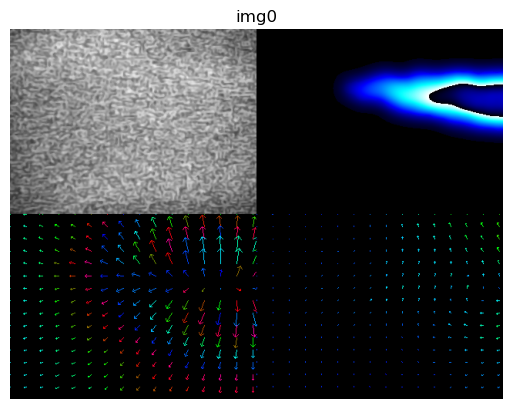

In [61]:
import matplotlib.pyplot as plt

sample_path = pkl_files[80]

with open(sample_path, "rb") as f:
    sample = pickle.load(f)

img0 = sample["img0"]  # shape (480, 640, 3), uint8

plt.imshow(img0)
plt.title("img0")
plt.axis("off")
plt.show()

<class 'torch.Tensor'>
torch.Size([1, 240, 320])


/tmp/ipykernel_1601607/218024095.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  data = torch.load(file_path)


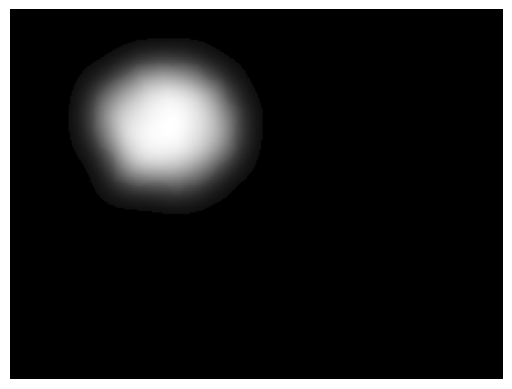

In [73]:
import torch
import matplotlib.pyplot as plt

# 파일 경로
file_path =file_path = "processed_data/cross_modal/large_ball/daimon/large_ball_val/ep0000_fr0035.pt"

data = torch.load(file_path)

img = data['image']  # 핵심

print(type(img))
print(img.shape)

# tensor → numpy
img = img.squeeze().cpu().numpy()

plt.imshow(img, cmap='gray')
plt.axis("off")
plt.show()